# Frequency, severity and pure premium models: summary

This is the short version of `03_glm.ipynb`. It loads the tables and charts that the full notebook saved in
`outputs/m3_draft/`, and it never fits a model, so it runs in seconds. The full notebook has the evidence for every
decision, and the diagrams of the data flow and the decision rules are in [_docs/data-flow.md](../_docs/data-flow.md).

**The problem.** A pricing reviewer wants to see how the pure premium of a UK-style individual private medical insurance
(PMI) policy can be built from claims experience, and how far each modelling choice can be trusted. The pure premium is the
expected claims cost of a person for a year of cover, before expenses, margin and tax. It is built from a frequency model (the
chance of a claim) and a severity model (the cost of a claim).

**Data and UK framing.** The data are the Medical Expenditure Panel Survey (MEPS) of the US Agency for Healthcare Research and
Quality, for 2022 and 2023, with PMI-scope claims at 2023 prices. The 2022 rows are split by household into a train split and
a test split that is held out, and 2023 is kept for a later out-of-time test. MEPS is US data, so it gives the shape of cost
and not UK levels. Only factors a UK insurer could use price the policy. Sex, race, income and education are excluded, and
US-specific or non-UK variables are analysis-only. All figures are aggregates.

## Key decisions and findings

Each decision below was made by the user at a decision gate, on the evidence in the section named. The last column names the
entry in `_docs/decisions.md` that records it.

| Decision or finding | Choice | Why | Section | Entry in `_docs/decisions.md` |
|---|---|---|---|---|
| Modelling frame | 2022 split by household into train and test, with 2023 held out | The yardstick is a holdout with no household on both sides | [Data and metrics](03_glm.ipynb#data-and-metrics) | Household-grouped split within 2022 |
| Benefit types | Inpatient and day-case against outpatient, using the surgical-procedure flag | A UK policy prices these separately, and the flag is the only direct indicator | [Benefit types](03_glm.ipynb#benefit-types) | Benefit types for the stacked candidate |
| Level grouping | Five-year age bands, thin and placeholder levels merged into the reference | Stable relativities, with at least 100 claimants in every age band | [Rating-factor levels](03_glm.ipynb#rating-factor-levels-decision-gate-6) | Rating-factor level grouping |
| Large claims | Cap of 100,000 dollars per person-year, with a provisional flat load of 6.5 percent | The cap affects 32 train claimants and removes 6.1 percent of cost | [Large claims](03_glm.ipynb#large-claims-decision-gate-5) | Large-claim cap and provisional load |
| Model structure | (a) Binomial-cloglog × Gamma | Best on the test split at three Tweedie powers, and it survives a multiplicative form | [Model comparison](03_glm.ipynb#model-comparison) | Model structure and the surrogate model (tariff) check |
| Permitted factors | Age, region and seven condition flags price the policy | The factor rule is p below 0.05 and an AIC gain, and the flags stand in for underwriting | [Permitted rating factors](03_glm.ipynb#permitted-rating-factors-decision-gate-7-part-2) | Permitted factors and the final factor set |
| Smoking | Analysis-only, with no smoker discount | The discount is not explained by the condition flags and fits lower use of care | [Smoking check](03_glm.ipynb#smoking-check-decision-gate) | Smoking and age decisions |
| Age | Tariff band relativities read off a smooth curve, with five-year bands as the table format | Preferred in the train data, and it removes irregularities between bands | [Age curve](03_glm.ipynb#age-curve-bands-or-a-smooth-curve-decision-gate) | Smoking and age decisions |
| Rebalancing | The base rate is rescaled so that train predicted cost equals train actual cost | Analysis-only factors are priced at their reference level, which leaves the base rate too low | [Permitted rating factors](03_glm.ipynb#permitted-rating-factors-decision-gate-7-part-2) | Permitted factors and the final factor set |
| Exercise | An insight and not a rating factor | The raw gap of 31 percent disappears after adjustment | [Permitted rating factors](03_glm.ipynb#permitted-rating-factors-decision-gate-7-part-2) | Permitted factors and the final factor set |

### Headline numbers

All scores are on the 2022 test split, which has 4,151 person-years and 1,731 claimants, so small differences are within
sampling noise. The lowest deviance is best, and the highest Gini is best.

| Measure | Value |
|---|---|
| Baseline test deviance (overall mean) | 928,364 |
| (a) Binomial-cloglog × Gamma, all factors | deviance 808,193 (12.9 percent below the baseline), Gini 0.433 |
| (b) Poisson × Gamma | deviance 816,054 (12.1 percent below the baseline) |
| (a) Surrogate model (tariff) | deviance 814,292 (12.3 percent below the baseline), Gini 0.426 |
| (a) Final structure, 9 rating factors | deviance 830,232 (10.6 percent below the baseline), Gini 0.393 |
| Final tariff, 26 parameters | deviance 838,173 (9.7 percent below the baseline), Gini 0.378, A/E 1.081 (band 0.90 to 1.28) |
| Smoking relativity | daily 0.60 and occasional 0.69, and daily is 0.74 when self-rated health is also left out |
| Exercise, adjusted | frequency 0.97 and severity 1.07, both consistent with no effect |

The final rating factors are age, region and the condition flags for high blood pressure, coronary heart disease, other
heart disease, cholesterol, cancer, arthritis and asthma. Self-rated health, exercise, `inscov` and smoking are analysis-only.
The saved charts are in `outputs/m3_draft/figures/` and the saved tables are in `outputs/m3_draft/`.

### Headline numbers from the saved tables

The table below is read from the files named in its last column.

In [1]:
import pandas as pd
from IPython.display import Image

from health_pricing.models import figures, summary

pd.options.display.float_format = "{:,.3f}".format
summary.headline_numbers()

,number,value,source
0,Baseline test deviance (p = 1.5),"928,364",model_comparison.csv
1,"(a) Binomial-cloglog × Gamma, all factors, tes...","808,193 (12.9 percent below the baseline)",model_comparison.csv
2,"(a) Binomial-cloglog × Gamma, all factors, tes...",0.433,model_comparison.csv
3,"(b) Poisson × Gamma, test deviance","816,054 (12.1 percent below the baseline)",model_comparison.csv
4,"(a) Surrogate model (tariff), test deviance","814,292 (12.3 percent below the baseline)",model_comparison.csv
5,"(a) Surrogate model (tariff), test Gini",0.426,model_comparison.csv
6,"(a) Final structure (9 factors), test deviance","830,232 (10.6 percent below the baseline)",permitted_factor_options.csv
7,"(a) Final structure (9 factors), test Gini",0.393,permitted_factor_options.csv
8,"Final tariff, test deviance","838,173 (9.7 percent below the baseline)",final_scores.csv
9,"Final tariff, test Gini",0.378,final_scores.csv


## Model specifications

The chosen model and the final tariff are written out below. The full notebook has the equations of every candidate, the
notation, and the definition of the yardstick.

### (a) Binomial-cloglog × Gamma

**Frequency.** $N_i \sim \text{Bernoulli}(p_i)$ with a complementary log-log link and an offset of $\log t_i$ (its coefficient is fixed at 1)

$$\text{cloglog}(p_i) = \log\!\big(-\log(1 - p_i)\big) = \log t_i + \mathbf{x}_i^{\top}\boldsymbol\beta, \qquad p_i = 1 - \exp\!\big(-t_i\, e^{\mathbf{x}_i^{\top}\boldsymbol\beta}\big).$$

This is a constant claim rate $\lambda_i = e^{\mathbf{x}_i^{\top}\boldsymbol\beta}$ per year, with $p_i$ the chance of at least one claim during the exposure $t_i$.
Every row has weight 1.

**Severity.** For claimants only, $S_i \mid N_i = 1 \sim \text{Gamma}(\mu_i, \phi)$ with mean $\mu_i$ and variance $\phi\,\mu_i^2$, a log link, no offset and weight 1

$$\log \mu_i = \mathbf{x}_i^{\top}\boldsymbol\gamma.$$

**Expected annual cost.**

$$\hat y_i = p_i \, \mu_i \, (1 + \ell).$$

**Assumptions.** Person-years are independent, so household members are not modelled as correlated, and the uncertainty bands later in
the notebook resample households. The standard errors are model based. The claim rate is constant within the year. Factor effects are multiplicative on the claim rate and on the
severity. The severity has a constant coefficient of variation $\sqrt{\phi}$. Costs above the cap are replaced by the flat
load. The number of claims is never a weight or a predictor.

### Final structure, the smooth age model and the surrogate model (tariff)

**Final structure.** Candidate (a) with the 9 rating factors, scored as the final structure, with adult age in five-year
bands. The factor vector $\mathbf{x}_i$ holds the rating factors (age, region and seven condition flags) and also the
analysis-only controls (self-rated health, exercise, `inscov` and smoking). The controls adjust the other coefficients
and are set to their reference level when pricing, so $p_i$ and $\mu_i$ below are evaluated with the controls at their
reference level. The prediction is rebalanced

$$\hat y_i = \rho\, p_i \, \mu_i \, (1 + \ell), \qquad \rho = \frac{\sum_{i \in \text{train}} Y_i}{\sum_{i \in \text{train}} p_i\, \mu_i\, (1 + \ell)}.$$

**Smooth age model.** The same model with the adult age bands replaced by a natural cubic spline. Age enters as the child
bands and, for adults of age $u_i \geq 18$ (capped at 85), as

$$\mathbf{x}_i^{\top}\boldsymbol\beta = \dots + \sum_{k=1}^{4} \beta_k\, B_k(u_i)\, \mathbb{1}[\text{adult}_i],$$

where $B_1(u) = u$ and $B_2, B_3, B_4$ are restricted cubic spline terms that are linear beyond the outer knots, with five knots at the
5th, 27.5th, 50th, 72.5th and 95th percentiles of the adult ages of the train split. The same form holds for the severity
coefficients $\boldsymbol\gamma$, and the prediction is rebalanced in the same way. This is the model that the final tariff is
fitted to.

**Surrogate model (tariff).** A multiplicative model fitted to the predictions $\hat y_i$ of the smooth age model, and not to
claims. The response is $\hat y_i$, with a Poisson family (used as a quasi-likelihood), a log link, an offset of $\log t_i$ and weight 1

$$\log \tilde y_i = \log t_i + \mathbf{z}_i^{\top}\boldsymbol\kappa, \qquad \tilde y_i = t_i \, r_0 \prod_{k} r_{k,\, l_k(i)}, \qquad r = e^{\kappa}.$$

Here $\mathbf{z}_i$ holds only the rating factors, with age in five-year bands, $r_0$ is the base rate per year of exposure and
$r_{k, l}$ is the relativity of level $l$ of factor $k$ (1 for the reference level). The fitted tariff keeps the total
predicted cost, $\sum_i \tilde y_i = \sum_i \hat y_i$ on train. Its relativities are the final tariff, and its age bands are read
off the smooth curve.

**Assumptions.** The effects of the factors are exactly multiplicative and cost is proportional to exposure. The tariff is
an approximation to the smooth age model. It departs from the banded final structure by a median of 5.5 percent, which
includes the smoothing of age.

### Comparison of the specifications

The parameter counts of the first five rows are for the comparison stage, with all 18 candidate factors. The last three rows are for the final structure, with its 9 rating factors and 5 analysis-only controls. A parameter is a coefficient of the frequency part plus a coefficient of the severity part. The dispersion is not counted.

| Model | Frequency part | Severity part | Expected annual cost | Multiplicative | Parameters |
|---|---|---|---|---|---|
| (a) Binomial-cloglog × Gamma | Binomial, cloglog, offset $\log t_i$ | Gamma, log | $p_i\,\mu_i\,(1+\ell)$ | No, the claim chance cannot exceed 1 | 88 |
| (b) Poisson × Gamma | Poisson, log, offset $\log t_i$ | Gamma, log | $m_i\,\mu_i\,(1+\ell)$ | Yes | 88 |
| (c) Stacked by benefit type | Binomial, cloglog, benefit-type effect | Gamma, log, benefit-type effect | $(1+\ell)\sum_b p_{ib}\,\mu_{ib}$ | No | 90 |
| (c) Stacked with age × benefit interaction | As (c), with age × benefit-type terms | As (c) | $(1+\ell)\sum_b p_{ib}\,\mu_{ib}$ | No | 105 |
| (a) Surrogate model (tariff) | None, a single Poisson-log model of (a)'s predicted cost | None | $t_i\,r_0\prod_k r_{k,\,l_k(i)}$ | Yes | 43 |
| (a) Final structure, 9 rating factors | Binomial, cloglog, age bands | Gamma, log, age bands | $\rho\,p_i\,\mu_i\,(1+\ell)$ | No | 80 |
| (a) Final structure with a smooth age curve | Binomial, cloglog, age spline | Gamma, log, age spline | $\rho\,p_i\,\mu_i\,(1+\ell)$ | No | 64 |
| (a) Final tariff | None, a Poisson-log model of the smooth age model's cost | None | $t_i\,r_0\prod_k r_{k,\,l_k(i)}$ | Yes | 26 |

The deviance of a model is $D = \sum_i d_{1.5}(Y_i, \hat y_i)$, the Tweedie deviance with power 1.5 over the test split, and the
Gini is the exposure-weighted Gini of the ranking by predicted cost per exposure year. Both are defined in
`03_glm.ipynb`. The reduction against the baseline is $100\,(1 - D_{\text{model}}/D_{\text{baseline}})$ percent.

## Key charts

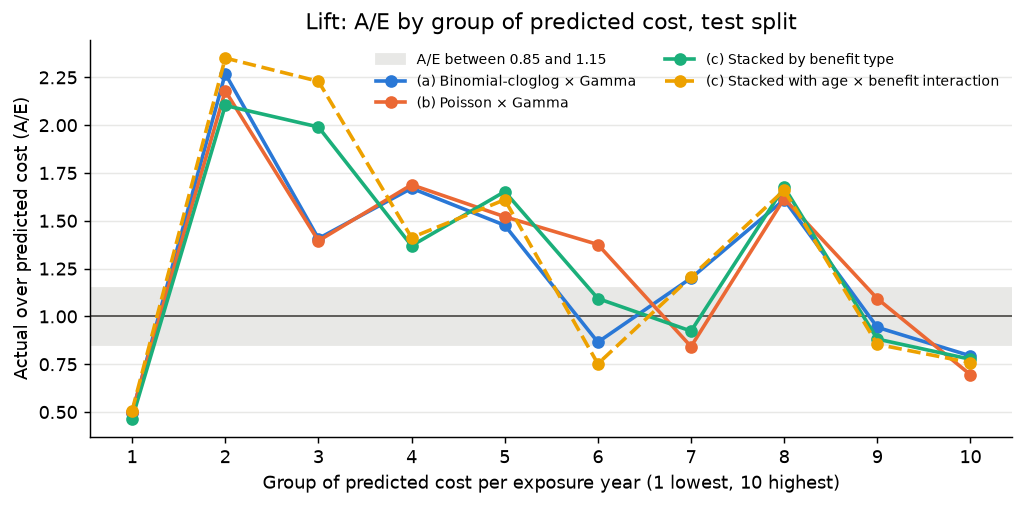

In [2]:
Image(filename=str(figures.FIGURES_DIR / "lift_candidates.png"))

**Candidates on the test split.** The chart shows A/E (actual over predicted cost) by group of predicted cost per exposure
year. The four candidates move together, with the lowest group over-predicted and some middle groups under-predicted, so the
pattern belongs to this small, heavy-tailed test split and not to one structure. Candidate (a) has a test deviance of
808,193 (12.9 percent below the baseline) and a Gini of 0.433, against
928,364 for the overall mean.

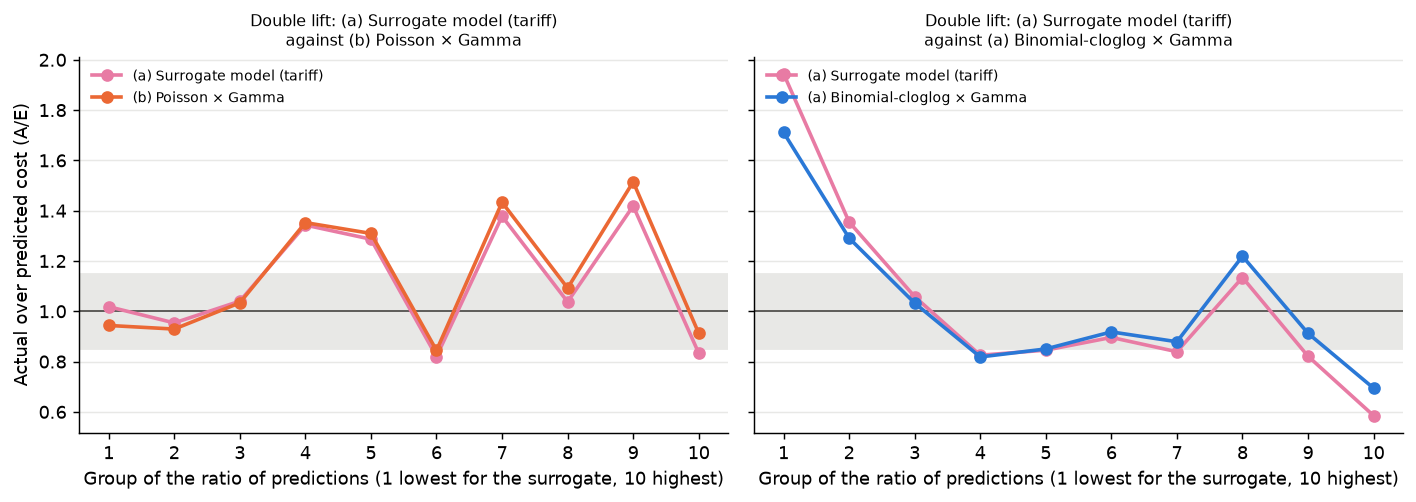

In [3]:
Image(filename=str(figures.FIGURES_DIR / "double_lift_surrogate.png"))

**Does the choice survive a multiplicative form.** A rating engine multiplies relativities, and candidate (a) is not exactly
multiplicative. The left panel compares its surrogate model (tariff), a multiplicative model fitted to (a)'s predicted cost,
with candidate (b), which is already multiplicative. The tariff has the lower deviance (814,292 (12.3 percent below the baseline) against
816,054 (12.1 percent below the baseline)) and is nearer 1 in 7 of 10 groups, so (a) is confirmed. The margin is small and within
sampling noise.

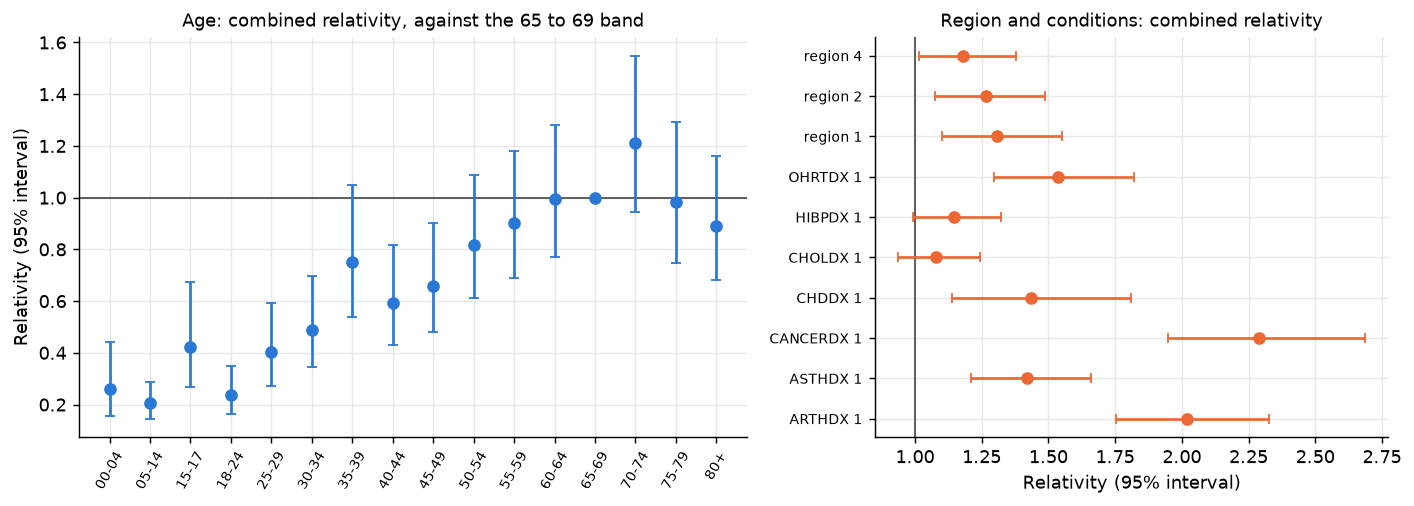

In [4]:
Image(filename=str(figures.FIGURES_DIR / "relativities_final.png"))

**Relativities of the final structure.** The final structure prices on age, region and seven condition flags. Against the 65 to 69
band, the combined age relativity is about 0.25 for ages 0 to 4 and 18 to 24 and peaks at 1.21 for ages 70 to 74, with wide
intervals. Cancer (2.29), arthritis (2.02), other heart disease (1.54), coronary heart disease (1.43) and asthma (1.42) carry
the largest condition loadings. The condition flags stand in for underwriting. The bounds on the combined relativities treat
frequency and severity as independent, so they are approximate.

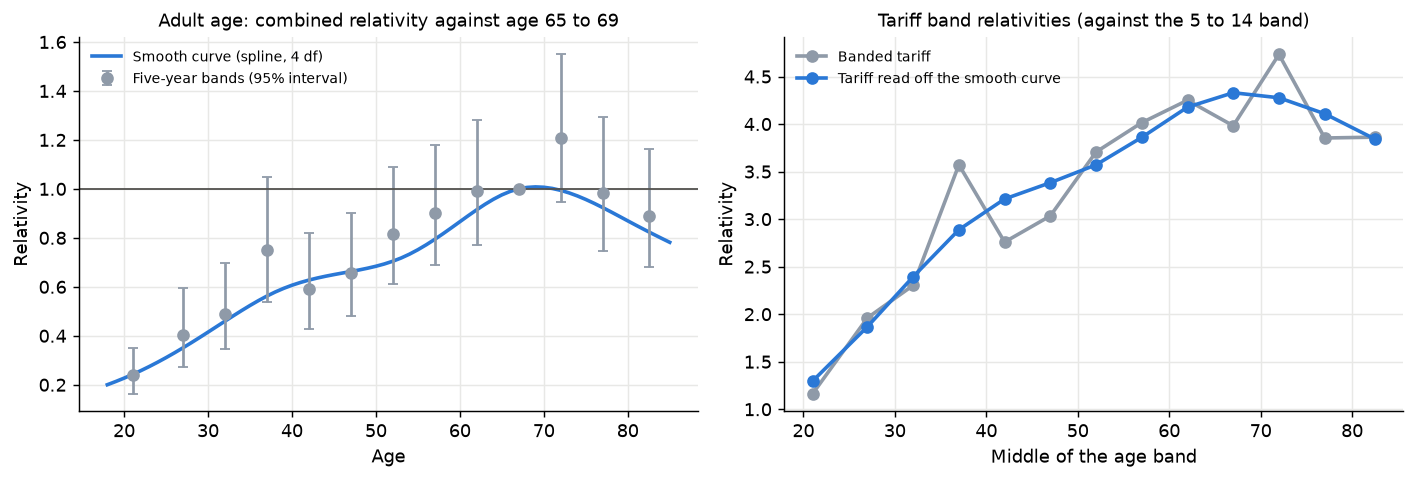

In [5]:
Image(filename=str(figures.FIGURES_DIR / "age_curve.png"))

**Smooth age curve.** A natural spline for adult age (4 degrees of freedom) has 16 fewer parameters than the five-year bands
and a lower AIC, and it adds something beyond the bands while the bands add nothing beyond it. On the test split the bands are
slightly better, which is within noise, so the preference is moderate. The tariff's band relativities are read off the smooth
curve, which removes the bumps and dips of the banded tariff, and the five-year bands stay as the table format.

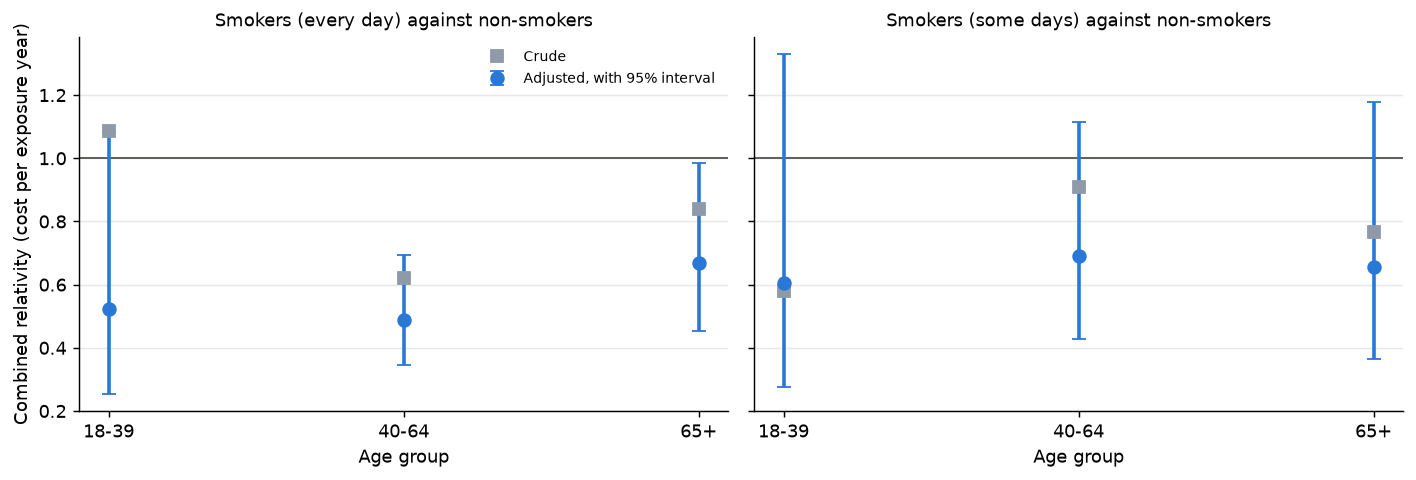

In [6]:
Image(filename=str(figures.FIGURES_DIR / "smoking_by_age_group.png"))

**Smoking.** Smokers appear cheaper than non-smokers, with a relativity of 0.60 for daily smokers and
0.69 for occasional smokers. Removing the condition flags does not change it, and leaving
out self-rated health as well raises it to only 0.74. The gap is
mostly in frequency and is already in the crude data. It fits the lower use of care seen in US survey data, and the data cannot
separate lower need from lower use. Smoking is therefore analysis-only and there is no smoker discount in the tariff.

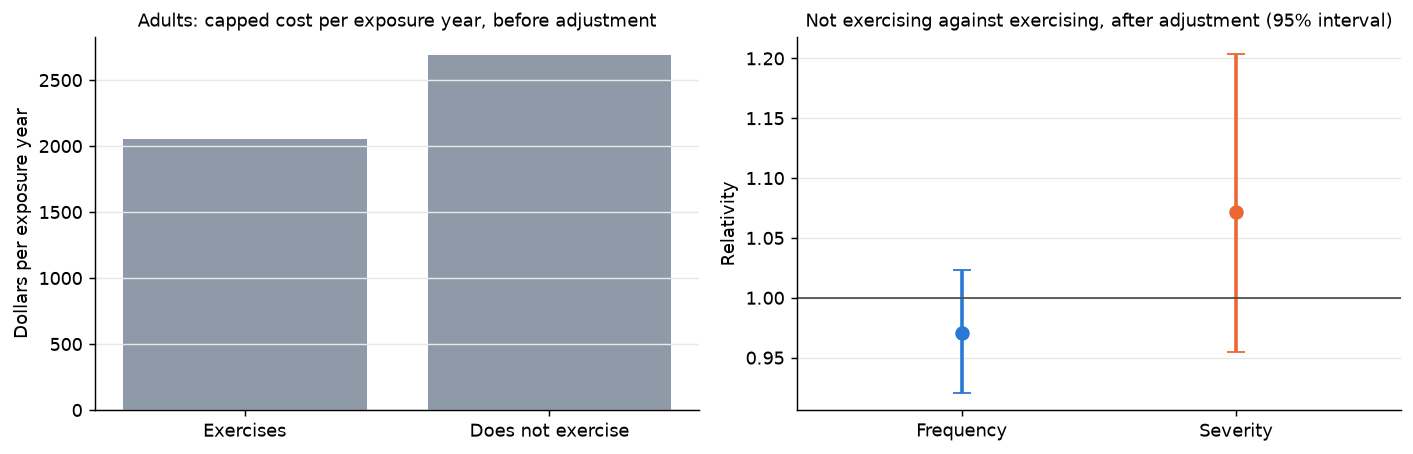

In [7]:
Image(filename=str(figures.FIGURES_DIR / "exercise_insight.png"))

**Exercise.** Adults who do not exercise cost 31 percent more per exposure year before
adjustment. After adjustment the relativities are 0.97 for frequency and
1.07 for severity, and both intervals include 1. The raw gap reflects who exercises and
not a causal effect, and estimating the effect would need a randomised design. Exercise is an insight and not a rating factor.

## Final tariff

The final tariff has five-year age bands whose relativities are read off the smooth curve, and it is exactly multiplicative.
It is rebalanced on train so that predicted cost on train equals actual cost on train. The relativities are against the
reference level of each factor, and the presentation column shows age against the 65 to 69 band.

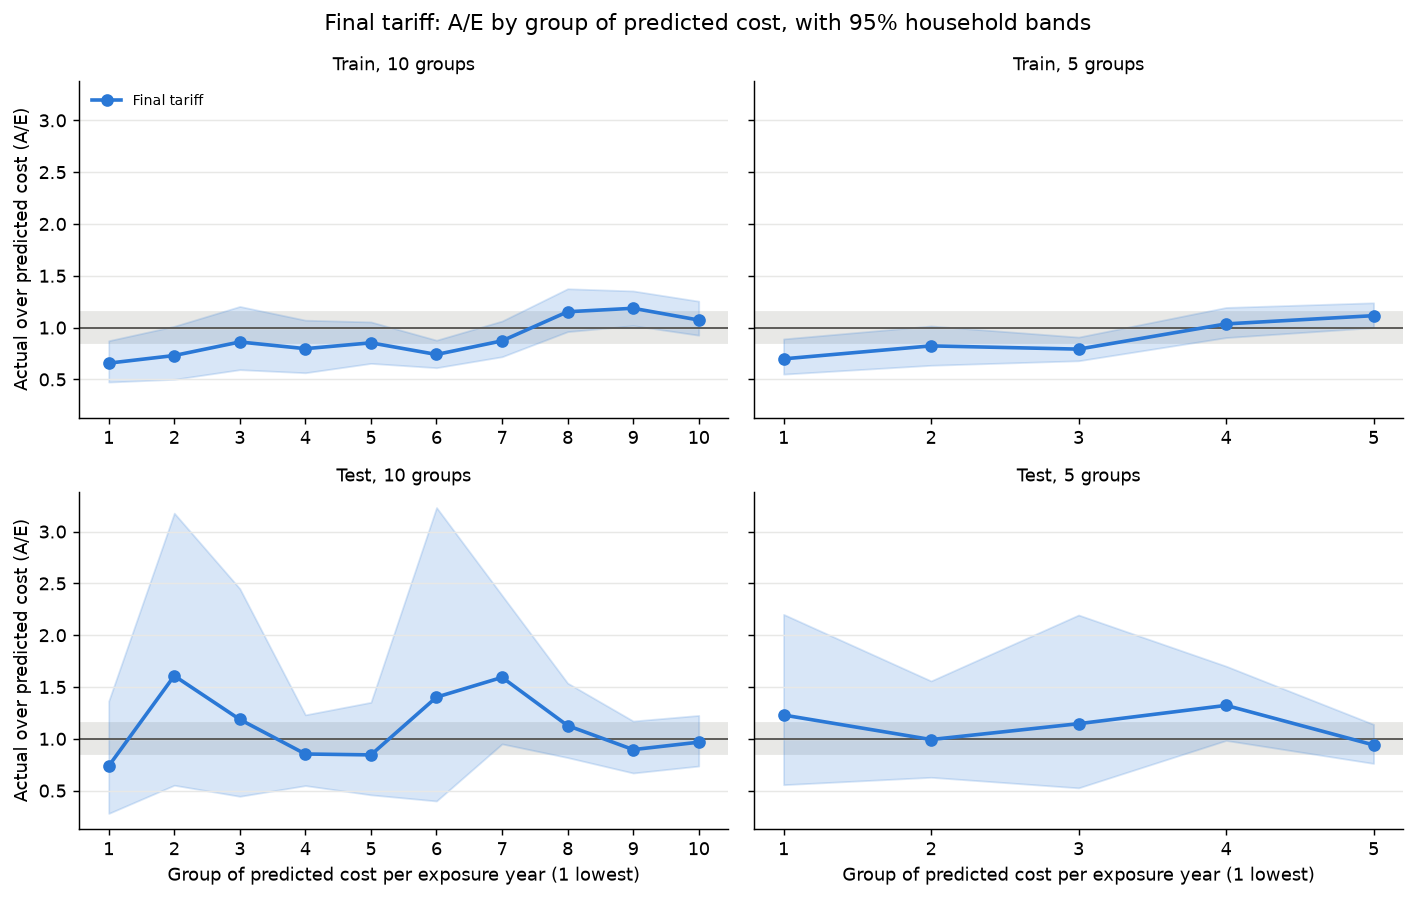

In [8]:
Image(filename=str(figures.FIGURES_DIR / "lift_final_tariff.png"))

**Lift of the final tariff.** The chart shows A/E by group of predicted cost per exposure year on train and test, in ten and five
groups, with 95 percent bands from resampling households. The tariff has a test deviance of
838,173 (9.7 percent below the baseline) and a Gini of 0.378. Its Gini is below the final structure's
(0.393). The gap is split about evenly between two steps. Smoothing age costs 0.007 of Gini (the same structure with
the smooth age curve has a Gini of 0.386) and the multiplicative approximation costs 0.008, because it cannot reproduce the
flattening of the claim chance for high-risk person-years. On deviance the multiplicative step is the larger part. This suggests
that the tariff loses some of the order of the person-years, which is all the Gini measures, and with 1,731 test claimants the
split between the two steps is uncertain.

In [9]:
tariff = summary.read("relativities_tariff.csv")
tariff[["factor", "level", "relativity", "presentation_relativity", "exposure", "claimants"]]

,factor,level,relativity,presentation_relativity,exposure,claimants
0,age,05-14,1.000,0.231,"2,002.417",368
1,age,00-04,1.301,0.300,693.250,106
2,age,15-17,1.985,0.459,634.000,150
3,age,18-24,1.296,0.299,"1,168.917",246
4,age,25-29,1.869,0.432,944.667,227
5,age,30-34,2.394,0.553,"1,019.583",302
6,age,35-39,2.889,0.667,"1,115.500",339
7,age,40-44,3.212,0.742,"1,046.167",370
8,age,45-49,3.383,0.781,994.333,386
9,age,50-54,3.571,0.825,"1,126.833",502


## Limitations

- **US data.** MEPS describes US use of care and prices. It gives the shape of cost, and the levels are not UK levels.
  Insurance cover type and access to care are US effects, and they are analysis-only.
- **A small, heavy-tailed test split.** The test split has 4,151 person-years and 1,731 claimants, with 11 above the
  large-claim cap. Differences between candidates and between factor sets are within sampling noise, and the test A/E of
  about 1.08 cannot be told from 1.00.
- **Provisional large-claim load.** The flat 6.5 percent load comes from the train split and is used for comparison only. It
  is to be re-estimated on the pooled 2022 and 2023 rows, preferably with a fitted tail distribution.
- **Conditions stand in for underwriting.** UK insurers usually exclude claims linked to pre-existing conditions, and
  modelling that needs a link from each condition to each claim. The condition loadings here overstate the loss that a
  policy with exclusions would pay.
- **Smoking.** Smokers appear cheaper in these data, which fits lower use of care and not lower need. Smoking is
  analysis-only, and any smoker loading would have to be a judgement loading from an external source.
- **Age curve.** The smooth curve is preferred in the train data and slightly worse on the test split, so the preference is
  moderate. Intervals for the combined relativities treat frequency and severity as independent, so they are approximate.
- **Tariff.** The final tariff is exactly multiplicative and departs from the banded structure by a median of 5.5 percent.
  Its relativities are point values with no interval.
- **Not yet done.** The 2023 out-of-time test, trend projection of the cap and the premium, expenses, margin and tax, and a
  gradient-boosting challenger are later work.